In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from agfx.gym import create_state, from_amat, enumerate_ancestral_graphs, AncestralGraph, get_indicators
from agfx.special.linear_gaussian import sample_from_graph
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet

In [2]:
# our graph will be A -> B <-> C -> D
dir_amat = jnp.array(
    [
        [0, 1, 0, 0], 
        [0, 0, 0, 0], 
        [0, 0, 0, 1], 
        [0, 0, 0, 0],
    ]
)

bidir_amat = jnp.array(
    [
        [0, 0, 0, 0], 
        [0, 0, 1, 0], 
        [0, 1, 0, 0], 
        [0, 0, 0, 0],
    ]
)

In [3]:
num_nodes = dir_amat.shape[1]
bs = 64
dmid = 64

iterations = int(5e3)
logr_t = LogRewardType.BIC
loss_t = LossType.CB

seed = 43

reward_seed = 43

In [4]:
all_graphs = enumerate_ancestral_graphs(num_nodes)

In [5]:
reward_key = jax.random.key(reward_seed)
# Simulate the data (which is needed for certain reward functions)
data, *_ = sample_from_graph(
    num_nodes, dir_amat, bidir_amat, num_samples=600, key=reward_key
)
true_graph = from_amat((dir_amat + bidir_amat)[None])

In [6]:
def train_gfn(seed: int, logr_t: LogRewardType, **kwargs):
    key = jax.random.key(seed)
    k1, k2 = jax.random.split(key, 2)

    state = create_state(bs, num_nodes)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid)
    # Create the reward function
    logr = create_log_reward(logr_t, data, true_graph, **kwargs)

    gfn, _ = train(gfn, state, k1, logr, iterations, loss_t)
    return gfn, state

In [7]:
gfn, state = train_gfn(seed, LogRewardType.BIC)

100%|██████████| 5000/5000 [00:55<00:00, 89.57it/s, loss=1.19e-03] 


In [8]:
logr = create_log_reward(logr_t, data, true_graph)

## Human in the loop

In [9]:
from mpl_preamble import *

In [10]:
from agfx.eitl import QueryMethod, expert, next_query, EIPolicy, mean_field_posterior
from agfx.policies import rollout, rollout_many
from agfx.evals import shd, eval_marginal

In [11]:
import numpy as np


def get_mode_amat(gfn, state, key, ei_policy):
    ei_policy.set_config(ei_policy.config.replace(greedy=True)) 
    mode_states, *_ = rollout(gfn, state, key, fpol=ei_policy)
    ei_policy.set_config(ei_policy.config.replace(greedy=False))

    return jnp.array(mode_states.amat[0])

In [12]:
# eval_marginal(gfn, state, logr, graphs=all_graphs, key=jax.random.key(seed), true_graph=true_graph)

In [13]:
def run(
    query_method: QueryMethod,
    seed: int,
    gfn: GFlowNet,
    state: AncestralGraph,
    n: int = 20,
    beta_rate: float = 0.8,
    pi: float = .999,
    pi_star: float = .999,
):
    key = jax.random.key(seed)
    ei_policy = EIPolicy(num_nodes, pi=pi)
    ei_policy.set_config(ei_policy.config.replace(beta_rate=beta_rate))

    true_graph_prob, shds_mode, mode_amats = [], [], []
    true_graph_ind = get_indicators(true_graph)

    for _ in range(n):
        rel, key = next_query(ei_policy, method=query_method, key=key, gfn=gfn, state=state)
        ans, key = expert(true_graph, pi=pi_star, rel=rel, key=key)
        ei_policy.update(rel, ans)


        samples = rollout_many(
            gfn, state, key, num_rollouts=10, fpol=ei_policy
        )
        edges_posterior = jax.vmap(get_indicators, in_axes=(0,), out_axes=0)(samples).mean(axis=(1, 0))
        
        true_graph_prob.append(
            jnp.max(true_graph_ind * edges_posterior, axis=2)
        )
    
        mode_amat = get_mode_amat(gfn, state, key, ei_policy)

        shds_mode.append(float(shd(from_amat(mode_amat[None]), true_graph)[0]))
        mode_amats.append(np.array(mode_amat))

        
    return true_graph_prob, shds_mode, mode_amats

In [14]:
true_graph_prob, shds_mode, mode_amats = run(
    QueryMethod.EDGES, seed=seed, gfn=gfn, state=state
)

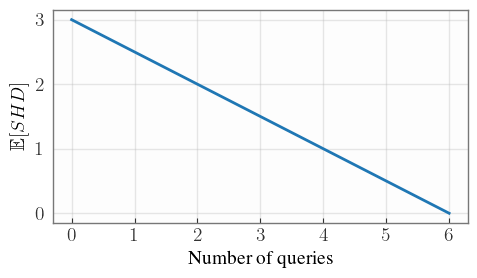

In [15]:
fig, ax = plt.subplots(figsize=(5, 3))
steps = [0, 2, 6]
ax.plot(steps, [shds_mode[i] for i in steps])
ax.set_xlabel(r"Number of queries")
ax.set_ylabel(r"$\mathbb{E}[SHD]$")
fig.tight_layout()
fig.savefig("figures/shd_evolution.pdf", bbox_inches="tight")
plt.show()

In [27]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from typing import Sequence


# ── drawing ──────────────────────────────────────────────────────────────────

def draw_graph(
    amat: np.ndarray,
    ax: plt.Axes,
    pos: dict,
    labels: list[str] | None = None,
    node_color: str = "steelblue",
    edge_color: str = "#333333",
    bidir_color: str = "tab:red",
    node_size: int = 700,
    font_size: int = 11,
    highlight: bool = False,
    pad: float = 0.40,
) -> None:
    """Draw a mixed directed / bidirected graph from an adjacency matrix.

    Symmetric 1-1 entries become bidirected (red ↔) edges;
    all other 1-entries become directed (black →) edges.

    Parameters
    ----------
    highlight : if True, draw a golden border around the axes to mark this
                panel as the "true graph".
    pad       : padding added around the unit-circle layout so nodes are
                never clipped by the axes boundary.
    """
    n = amat.shape[0]
    labels = labels or [str(i) for i in range(n)]

    sym        = (amat == amat.T) & (amat == 1)
    dir_amat   = np.where(sym, 0, amat)
    bidir_amat = np.where(sym, amat, 0)

    G = nx.DiGraph()
    G.add_nodes_from(range(n))
    G.add_edges_from(
        (i, j)
        for i in range(n)
        for j in range(n)
        if dir_amat[i, j]
    )

    # Explicit axis limits — prevents nodes being clipped at the boundary.
    ax.set_xlim(-1 - pad, 1 + pad)
    ax.set_ylim(-1 - pad, 1 + pad)

    # shrinkA/B in points ≈ radius of the drawn node circle
    node_radius_pt = (node_size / np.pi) ** 0.5 + 3

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=node_color, node_size=node_size, alpha=0.95,
    )
    nx.draw_networkx_labels(
        G, pos, ax=ax,
        labels={i: labels[i] for i in range(n)},
        font_color="white", font_size=font_size, font_weight="bold",
    )

    # Directed edges — use annotate so shrink is in points and arrows are crisp.
    for i in range(n):
        for j in range(n):
            if dir_amat[i, j]:
                ax.annotate(
                    "", xy=pos[j], xytext=pos[i],
                    arrowprops=dict(
                        arrowstyle="-|>",
                        color=edge_color,
                        lw=1.6,
                        mutation_scale=18,
                        shrinkA=node_radius_pt,
                        shrinkB=node_radius_pt,
                    ),
                )

    # Bidirected edges — curved double-headed arrows.
    for i in range(n):
        for j in range(i + 1, n):
            if bidir_amat[i, j]:
                ax.annotate(
                    "", xy=pos[j], xytext=pos[i],
                    arrowprops=dict(
                        arrowstyle="<|-|>",
                        color=bidir_color,
                        lw=1.6,
                        mutation_scale=18,
                        shrinkA=node_radius_pt,
                        shrinkB=node_radius_pt,
                        connectionstyle="arc3,rad=0.35",
                    ),
                )

    ax.set_axis_off()

    if highlight:
        # Re-enable spines after set_axis_off so the border remains visible.
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor("goldenrod")
            spine.set_linewidth(3.0)


# ── grid layout ───────────────────────────────────────────────────────────────

def plot_mode_graphs(
    mode_amats: Sequence[np.ndarray],
    steps: Sequence[int] | None = None,
    labels: list[str] | None = None,
    n_cols: int = 8,
    cell_size: tuple[float, float] = (2.6, 2.8),
    **draw_kwargs,
) -> plt.Figure:
    """Plot a grid of graphs for the given step indices.

    The last entry of *steps* is treated as the true graph and rendered with
    a golden border and bold title.  Pass ``selected_steps[-1]`` as the final
    element to match the intended usage (e.g. ``steps = [1, 3, 7, 12]``).

    Parameters
    ----------
    mode_amats : sequence of (n, n) adjacency matrices, one per step.
    steps      : integer indices into *mode_amats* to display.
                 Defaults to all steps.  The last index is highlighted as the
                 true graph.
    labels     : node label strings (length = n).
    n_cols     : maximum columns in the grid.
    cell_size  : (width, height) in inches per cell.
    **draw_kwargs : forwarded to :func:`draw_graph`.
    """
    if steps is None:
        steps = list(range(len(mode_amats)))

    steps = list(steps)

    bad = [s for s in steps if not (0 <= s < len(mode_amats))]
    if bad:
        raise IndexError(
            f"Step indices out of range [0, {len(mode_amats)-1}]: {bad}"
        )

    true_step   = steps[-1]
    selected    = [mode_amats[s] for s in steps]
    step_titles = [f"Step {s + 1}" for s in steps]
    step_titles[-1] = "Ground truth"

    n      = len(selected)
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols

    n_nodes = selected[0].shape[0]
    G_layout = nx.DiGraph()
    G_layout.add_nodes_from(range(n_nodes))
    pos = nx.circular_layout(G_layout)

    w, h = cell_size
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(n_cols * w, n_rows * h),
        squeeze=False,
    )
    axes_flat = axes.flatten()

    for idx, (ax, amat, title) in enumerate(zip(axes_flat, selected, step_titles)):
        is_true = (idx == n - 1)
        draw_graph(amat, ax=ax, pos=pos, labels=labels,
                   highlight=is_true, **draw_kwargs)
        ax.set_title(title, fontsize=10, pad=4,
                     fontweight="bold" if is_true else "normal",
                     color="goldenrod" if is_true else "black")

    for ax in axes_flat[n:]:
        ax.axis("off")

    legend_handles = [
        mpatches.Patch(color="steelblue", label="Node"),
        mpatches.Patch(color="#333333",   label="Directed"),
        mpatches.Patch(color="tab:red",   label="Bidirected"),
        mpatches.Patch(facecolor="none", edgecolor="goldenrod",
                       linewidth=2, label="True graph"),
    ]
    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=4,
        frameon=False,
        fontsize=10,
        bbox_to_anchor=(0.5, -0.02),
    )

    fig.tight_layout()
    return fig

<Figure size 600x400 with 0 Axes>

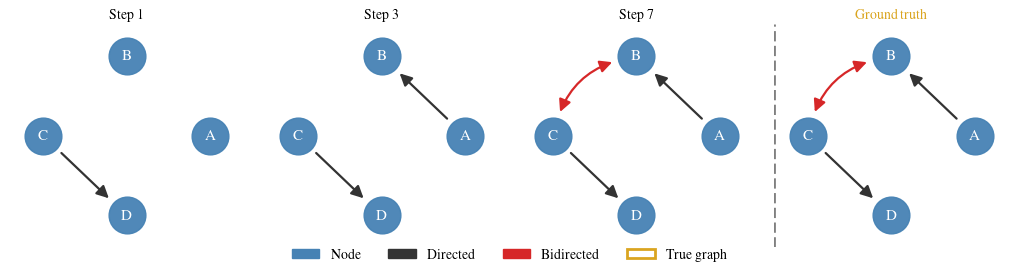

In [28]:
plt.figure(figsize=(6, 4))

selected_steps = steps + [steps[-1] + 1]   # ← edit this list

fig = plot_mode_graphs(
    mode_amats,
    steps=selected_steps,
    labels=list("ABCD"),
)

plt.axvline(x=-1.4, c="gray", linestyle="--")
fig.savefig("figures/mode_graphs.pdf", bbox_inches="tight")
plt.show()

In [18]:
true_graph_prob[6], state.pairs

(Array([[1.       , 1.       , 0.9984375, 0.7078125, 0.9921875, 1.       ]],      dtype=float32),
 Array([[0, 1],
        [0, 2],
        [0, 3],
        [1, 2],
        [1, 3],
        [2, 3]], dtype=int32))

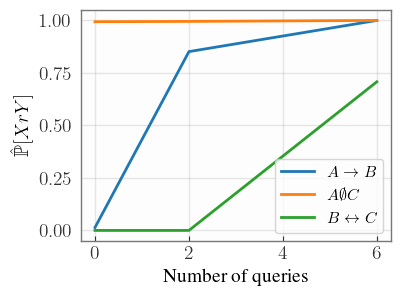

In [29]:
edges = [0, 1, 3]
idx_to_label = {
    0: "$A \\rightarrow B$",
    1: "$A \\emptyset C$",
    3: "$B \\leftrightarrow C$"
}

plt.figure(figsize=(4, 3)) 

tps = [true_graph_prob[i] for i in steps]
for edge in edges:
    p = [tp[:, edge] for tp in tps]
    plt.plot(steps, p, label=idx_to_label[edge])

plt.ylabel("$\\hat{\\mathbb{P}}[XrY]$")
plt.xlabel("Number of queries")
plt.legend()

plt.savefig("figures/edge_probabilities.pdf", bbox_inches="tight")